In [1]:
import config as cfg
import data
import analysis as an

In [2]:
tickers = list(cfg.STOCKS)
prices = data.get_prices_sek(tickers + [cfg.MARKET], cfg.START, cfg.END)
returns = data.weekly_returns(prices)
market = returns.pop(cfg.MARKET).dropna()
returns = returns.loc[market.index]
returns.tail()

,NVDA,MSFT,GOOGL,META,AMZN,AVGO,AMD,TSM,ASML.AS,ETN,...,JNJ,RHHBY,HM-B.ST,ESSITY-B.ST,NESN.SW,PG,KO,TELIA.ST,EQNR.OL,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-16,-0.067123,-0.012359,-0.032564,-0.014102,-0.048432,-0.091714,-0.131462,-0.090804,-0.079122,-0.090395,...,-0.023586,0.055204,0.041063,0.051953,0.087473,0.052513,0.065245,0.067051,0.048521,0.058243
2026-10-23,-0.019293,-0.013099,-0.064121,-0.098174,-0.012520,-0.025964,-0.027073,0.009678,-0.051059,-0.068519,...,0.027579,0.065651,0.014501,-0.002884,0.020519,0.012535,-0.017172,0.041460,0.060719,0.018970
2026-10-30,-0.035981,-0.011135,-0.131499,-0.048938,-0.036864,0.007385,-0.029265,-0.035606,-0.004308,0.004269,...,0.029164,-0.004584,0.017439,0.012292,0.001023,-0.002814,0.008477,0.034655,-0.011830,0.015706
2026-11-06,-0.091184,0.013075,0.014054,-0.011378,0.075028,-0.102516,-0.113605,-0.078836,-0.091035,-0.079624,...,0.007479,-0.034437,0.025007,0.035000,0.020074,0.020085,0.013305,-0.005469,-0.125631,-0.117311
2026-11-13,-0.034744,0.036001,0.020246,0.059907,0.037984,0.096857,0.142010,0.043711,0.042603,0.060187,...,0.029814,0.034648,0.008671,0.009317,0.001989,0.026115,0.012108,-0.003870,-0.061297,0.001384


In [ ]:
ai_factor, b = an.make_ai_factor(returns, market, cfg.AI_STOCKS)
b, ai_factor.corr(market)

(np.float64(1.4486170467910473), np.float64(-6.560275836590382e-16))

AI basket beta is about 1.45 vs the market. Correlation between the AI factor and the market is basically 0 (e-16 is just rounding), so removing the market part worked.

In [4]:
betas = an.all_betas(returns, market, ai_factor, cfg.STOCKS, cfg.AI_STOCKS)
betas.sort_values("beta_ai", ascending=False)[["name", "group", "beta_ai", "t_ai"]].head(15)

,name,group,beta_ai,t_ai
NVDA,Nvidia,direct_ai,1.099442,8.655704
AMD,AMD,direct_ai,1.085440,5.852090
AVGO,Broadcom,direct_ai,0.996413,7.330462
VRT,Vertiv,power_grid,0.902273,4.583419
TSM,TSMC,direct_ai,0.775906,8.605290
META,Meta,direct_ai,0.583868,4.731831
ASML.AS,ASML,direct_ai,0.500603,4.465264
CEG,Constellation,power_grid,0.457065,2.646846
AMZN,Amazon,direct_ai,0.433990,5.044131
GOOGL,Alphabet,direct_ai,0.408455,4.076877


Vertiv has a higher AI beta than Microsoft, Google and Amazon, even though it just makes cooling and power for data centers. Constellation, Eaton, Atlas Copco and Schneider also show up with t above 2. This is the hidden AI exposure. Hexagon is not significant (t = 1.8).

In [5]:
betas.sort_values("beta_ai")[["name", "group", "beta_ai", "t_ai"]].head(8)

,name,group,beta_ai,t_ai
JNJ,Johnson & Johnson,health,-0.615966,-9.333815
XOM,Exxon Mobil,energy,-0.587360,-6.130081
NEE,NextEra Energy,power_grid,-0.454822,-4.813292
KO,Coca-Cola,consumer,-0.427092,-7.657482
RHHBY,Roche,health,-0.424007,-4.860030
PG,Procter & Gamble,consumer,-0.417213,-7.454129
TELIA.ST,Telia,telecom,-0.397080,-5.451100
EQNR.OL,Equinor,energy,-0.367263,-2.795353


Defensives (J&J, Coca-Cola, P&G, Roche) have negative AI betas, they tend to go up when AI stocks fall. This partly cancels out the power & grid stocks, which is why the total portfolio AI beta looks small.

Interesting that NextEra is negative while Constellation is positive, both are utilities. So the sector label doesn't tell you much, you have to look at each company.

Want to check if the AI exposure has grown over time, or if it was always there. Rolling 52-week AI beta for a few power & grid stocks.

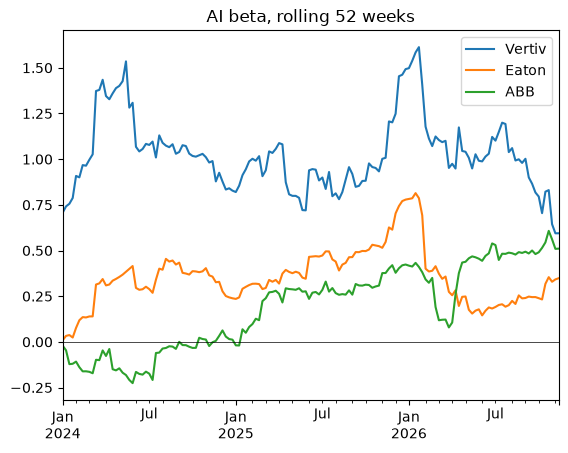

In [6]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

X = sm.add_constant(pd.concat([market, ai_factor], axis=1, keys=["mkt", "ai"]))

def rolling_ai_beta(ticker, window=52):
    df = pd.concat([returns[ticker], X], axis=1).dropna()
    out = {}
    for i in range(window, len(df) + 1):
        w = df.iloc[i - window:i]
        res = sm.OLS(w.iloc[:, 0], w[["const", "mkt", "ai"]]).fit()
        out[w.index[-1]] = res.params["ai"]
    return pd.Series(out)

for t in ["VRT", "ETN", "ABB.ST"]:
    rolling_ai_beta(t).plot(label=cfg.STOCKS[t][0])

plt.axhline(0, color="black", lw=0.5)
plt.legend()
plt.title("AI beta, rolling 52 weeks")
plt.show()

ABB is the clearest one, its AI beta went from around -0.2 in early 2024 to about 0.5 now. So it wasn't really an AI stock two years ago but it is now. This is the kind of thing TPR means by hidden exposure, it can grow without you changing the portfolio.

Eaton and Vertiv both drop suddenly around Feb 2026. I think that's because the DeepSeek week (Jan 2025) falls out of the 52-week window, one extreme week moves the beta a lot. So the rolling betas are quite noisy and I wouldn't trust single points too much.